# The immersed boundary method of Peskin & McQueen 1996, and where it lives in pyIBM

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fairyflies9/pyIBM/blob/main/tutorials/01_peskin_mcqueen_1996_immersed_boundary.ipynb)

This notebook walks through section 14 of Peskin & McQueen (1996), *Fluid dynamics of the heart and its valves* (chapter 14 of Othmer et al., *Case Studies in Mathematical Modeling*), which is the discrete scheme my 2008 MATLAB code implemented. We take the equations in the order the paper gives them, restate each one in our own words with its equation number, point at the pyIBM function that implements it, and run a short computation that shows it working. After that we do the same for the second-order midpoint scheme of Peskin (2002, *Acta Numerica*, section 7), which is pyIBM's default, for target points as tethers, and for the 2008 heaving plate, which we compare with the state the original MATLAB code saved.

The paper is written in three dimensions. We work in two, so throughout $h^3 \to h^2$, $\Delta q\,\Delta r\,\Delta s \to \Delta s$, and the $4^3 = 64$ lattice points a marker touches become $4^2 = 16$.

Everything here runs on coarse grids for a few hundred steps, so the computations take seconds (the last cell prints the time) and the whole notebook executes in a minute or two on a laptop, most of it imports and plotting. Where it matters, the text says what a converged run would use. The companion notebooks are `02_projection_method_mac_dirichlet` (the MAC-grid projection back end with walls) and `03_blob_projection_method` (the blob projection coupling).

In [1]:
# On Google Colab, fetch the repository first: the notebook reads example inputs and test data from it.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isfile(os.path.join("..", "pyibm", "__init__.py")):
    if not os.path.isdir("pyIBM"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/fairyflies9/pyIBM.git"], check=True)
    os.chdir(os.path.join("pyIBM", "tutorials"))

import os
import sys
import time
import tempfile

# The repository root: walk up from the working directory until pyibm/ is found, so the
# notebook runs from tutorials/ (jupyter lab from the repository root) without pip install.
root = os.getcwd()
while not os.path.isfile(os.path.join(root, "pyibm", "__init__.py")):
    parent = os.path.dirname(root)
    if parent == root:
        raise RuntimeError("run this notebook from inside the pyIBM repository")
    root = parent
if root not in sys.path:
    sys.path.insert(0, root)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

import pyibm
print("pyibm", pyibm.__version__)
print("numpy", np.__version__)
t_notebook_start = time.perf_counter()

pyibm 0.1.0.dev0
numpy 1.26.4


## 1. The periodic lattice: `pyibm.grid.Grid`

The paper puts the fluid on a periodic cube of side $L$ (p. 321): mesh width $h = L/N$, lattice points $x = jh$ with integer $j$ in $\{0, \dots, N-1\}$, and all index arithmetic modulo $N$. Periodic boundaries are chosen because the FFT solves the linear system of section 5 exactly, and the paper argues they are less restrictive than rigid walls: fluid may leave through one face as long as it comes back through the opposite one.

In pyIBM the lattice is `Grid.periodic_box(Lx, Ly, Nx, Ny)`. Nodes sit at $x_i = i\,\Delta x$, $y_j = j\,\Delta y$; arrays are shaped `(Nx, Ny)` and indexed `[i, j]` with `i` along $x$ (the MATLAB convention; `docs/numerics.md` lists the conventions); the FFT back end requires $\Delta x = \Delta y = h$. The modulo-$N$ arithmetic lives in `grid.wrap` (positions into $[0, L)$) and `grid.min_image` (separations reduced to the shortest periodic image). The 2008 case is a $0.4\,\mathrm{m}$ box with $16 \times 16$ cells, so we build that one.

In [2]:
from pyibm.grid import Grid

g16 = Grid.periodic_box(Lx=0.4, Ly=0.4, Nx=16, Ny=16)
print(g16)
print(f"h = dx = dy = {g16.dx} m; first nodes x = {g16.x[:4]}; field shape {g16.shape_p()}")

# index arithmetic modulo N: positions wrap, separations take the minimum image
X_out = np.array([[0.45, -0.01], [0.39, 0.20]])
print("wrap     :", g16.wrap(X_out).tolist())
print("min_image:", g16.min_image(X_out[1] - X_out[0]).tolist(), "(raw difference", (X_out[1] - X_out[0]).tolist(), ")")

Grid(Lx=0.4, Ly=0.4, Nx=16, Ny=16, periodic_x=True, periodic_y=True, dx=0.025, dy=0.025)
h = dx = dy = 0.025 m; first nodes x = [0.    0.025 0.05  0.075]; field shape (16, 16)
wrap     : [[0.04999999999999999, 0.39], [0.39, 0.2]]
min_image: [-0.06, -0.19] (raw difference [-0.06, 0.21000000000000002] )


## 2. Fiber forces and force spreading (eqs. 14.23-14.27)

The paper's immersed structure is a collection of elastic fibers parametrised by $s$, sampled at $s = m\,\Delta s$. Eq. 14.23 defines the centred difference along a fiber, $(D_s\phi)(s) = [\phi(s + \Delta s/2) - \phi(s - \Delta s/2)]/\Delta s$. The tension at the half points is a constitutive function of the stretch, $T^n = \sigma(|D_s X^n|)$ (eq. 14.24), the unit tangent is $\tau^n = D_s X^n / |D_s X^n|$ (eq. 14.25), and the force density on the fiber is the divergence of the tension, $f^n = D_s(T^n \tau^n)$ (eq. 14.26), defined at the same $s$ values as $X^n$. Eq. 14.27 (restated as eq. 14.58) spreads it to the lattice:

$$F^n(x) = \sum_{s} f^n(s)\, \delta_h\big(x - X^n(s)\big)\, \Delta s ,$$

with $\delta_h$ the smoothed delta function of section 7 below. Two conventions carry over to pyIBM exactly: $f$ is a force **per unit fiber length** (N/m in 2D), and every marker carries its quadrature weight $\Delta s$ (we call it `ds`, one value per point), which the spreading multiplies in. $F$ is then a body force per unit area (N/m$^2$).

pyIBM does not implement the fiber tension $\sigma$ of eq. 14.24 as such; its elastic elements (springs, beams, targets in `pyibm.structures`, section 9) are the discrete-energy forces of Peskin 2002 eqs. 4.5-4.6, $f = -\partial E/\partial X$ per unit length. Eq. 14.27 itself is `DeltaCoupling.spread(f, X, ds, layout)` in `pyibm.coupling.delta`: it accumulates the $4 \times 4$ stencil of every point with `np.bincount`, and a `FieldLayout` says where the grid field lives (the collocated nodes here; the MAC faces in notebook 02). A unit force density at one point with `ds = 0.01` m lands on exactly 16 nodes and integrates back to $f\,\Delta s$:

nodes touched: 16 (i = 7..10, j = 6..9)
sum_ij F_ij h^2 = 0.010000000000000  (f ds = 0.01: total force conserved, eq. 14.66)


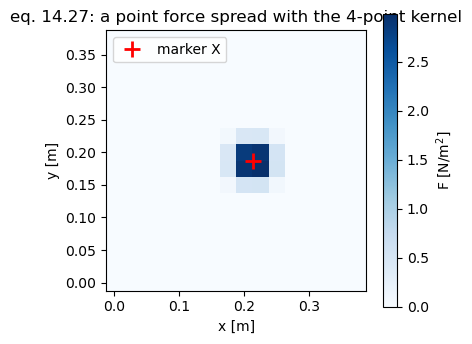

In [3]:
from pyibm.coupling.delta import DeltaCoupling
from pyibm.grid import layout_collocated

dc = DeltaCoupling("peskin4")             # the kernel of eq. 14.73, section 7
lay16 = layout_collocated(g16)            # nodes x_i = i h, y_j = j h, periodic

X1 = np.array([[0.213, 0.187]])           # one marker, off the lattice
F1 = dc.spread(np.array([1.0]), X1, np.array([0.01]), lay16)
nz = np.argwhere(F1 != 0.0)
print(f"nodes touched: {np.count_nonzero(F1)} (i = {nz[:, 0].min()}..{nz[:, 0].max()}, j = {nz[:, 1].min()}..{nz[:, 1].max()})")
print(f"sum_ij F_ij h^2 = {F1.sum() * g16.dx * g16.dy:.15f}  (f ds = 0.01: total force conserved, eq. 14.66)")

fig, ax = plt.subplots(figsize=(4.2, 3.8))
m = ax.pcolormesh(g16.x, g16.y, F1.T, shading="nearest", cmap="Blues")   # arrays are [i, j]; pcolormesh wants rows along y
ax.plot(X1[0, 0], X1[0, 1], "r+", ms=12, mew=2, label="marker X")
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("eq. 14.27: a point force spread with the 4-point kernel")
ax.legend(loc="upper left"); fig.colorbar(m, ax=ax, label="F [N/m$^2$]")
plt.show()

## 3. The fluid step and upwind advection (eqs. 14.28-14.39)

With $F^n$ on the lattice, the paper advances the fluid by the implicitly defined step (eqs. 14.28-14.29)

$$\rho\left[\frac{u^{n+1} - u^n}{\Delta t} + \sum_\alpha u^n_\alpha D^\pm_\alpha u^n\right] + D^0 p^{n+1} = \mu \sum_\alpha D^+_\alpha D^-_\alpha u^{n+1} + F^n, \qquad D^0 \cdot u^{n+1} = 0 .$$

We write the pressure term as $+D^0 p^{n+1}$, the sign it has in eq. 14.40 (eq. 14.28 multiplied by $\Delta t/\rho$) and in pyIBM.

The operators are the centred difference $D^0_\alpha \phi = [\phi(x + h e_\alpha) - \phi(x - h e_\alpha)]/2h$ (eqs. 14.30-14.31) for the pressure gradient and the divergence, and the one-sided differences $D^\pm_\alpha$ (eqs. 14.32-14.33); $\sum_\alpha D^+_\alpha D^-_\alpha$ is the tight five-point Laplacian. Advection is explicit and upwind (eq. 14.34): forward difference where the advecting component $u_\alpha$ is negative, backward where it is positive. The viscous term and the pressure are implicit (backward Euler).

The paper motivates the upwind choice with the scalar transport equation (eqs. 14.35-14.36): the upwind update is a weighted average of neighbouring values (eq. 14.37) as long as the CFL condition $\Delta t \sum_\alpha |u^n_\alpha| \le h$ holds (eq. 14.38), so the maximum norm cannot grow (eq. 14.39). It is only first-order accurate, as the paper says on p. 320, and it adds numerical diffusion.

In `pyibm.fluid.periodic_fft`: `d0x`, `d0y`, `divergence` and `laplacian` are the operators, `PeriodicFFTSolver.upwind_advection(u, v)` is eq. 14.34 applied to both components, and `solver.cfl()` returns $\Delta t \max(|u| + |v|)/h$. We watch eq. 14.39 at work on a ridge of $v$ carried by a uniform $u = U_0$ with $\mu = 0$ (a shear wave, discretely divergence-free because $v$ depends on $x$ only, so the projection leaves it alone): the exact solution translates without change, the upwind scheme flattens it but never overshoots.

32 upwind steps at CFL = dt U0/h = 0.50; the ridge travels 0.250 box lengths
max v: initial 0.9985, exact 0.9985, upwind 0.7864  (eq. 14.39: never above the initial value)
min v: upwind 1.50e-11 (no undershoot either)
box mean of v: initial 0.141796, upwind 0.141796
largest |D0 . u| after the run: 0.0e+00


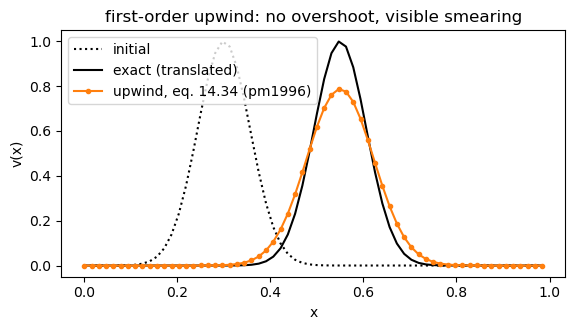

In [4]:
from pyibm.fluid.periodic_fft import PeriodicFFTSolver, d0x, d0y, divergence, laplacian

g_adv = Grid.periodic_box(1.0, 1.0, 64, 64)
U0 = 1.0                                        # m/s, the uniform advecting velocity
Xn, Yn = g_adv.meshgrid("nodes")
ridge = np.exp(-((Xn - 0.3) / 0.08) ** 2)       # v(x, 0): a Gaussian ridge, D0 . (U0, v(x)) = 0
dt_adv = 0.5 * g_adv.dx / U0                    # CFL 0.5 by eq. 14.38
n_adv = 32


def advect_ridge(scheme):
    s = PeriodicFFTSolver(g_adv, rho=1.0, mu=0.0, dt=dt_adv)    # mu = 0: pure advection
    s.u[:] = U0
    s.v[:] = ridge
    zero = np.zeros(g_adv.shape_p())
    for _ in range(n_adv):
        if scheme == "pm1996":
            s.step(zero, zero, 0.0)                              # section 4-5
        else:
            u_h, v_h = s.half_step(zero, zero, 0.0)              # section 8
            s.full_step(zero, zero, u_h, v_h, 0.0)
    return s


shift = U0 * n_adv * dt_adv
exact = np.exp(-((np.mod(Xn - shift - 0.3 + 0.5, 1.0) - 0.5) / 0.08) ** 2)
s_up = advect_ridge("pm1996")
print(f"{n_adv} upwind steps at CFL = dt U0/h = {dt_adv * U0 / g_adv.dx:.2f}; the ridge travels {shift:.3f} box lengths")
print(f"max v: initial {ridge.max():.4f}, exact {exact.max():.4f}, upwind {s_up.v.max():.4f}  (eq. 14.39: never above the initial value)")
print(f"min v: upwind {s_up.v.min():.2e} (no undershoot either)")
print(f"box mean of v: initial {ridge.mean():.6f}, upwind {s_up.v.mean():.6f}")
print(f"largest |D0 . u| after the run: {np.max(np.abs(divergence(s_up.u, s_up.v, g_adv.dx))):.1e}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(g_adv.x, ridge[:, 0], "k:", label="initial")
ax.plot(g_adv.x, exact[:, 0], "k-", label="exact (translated)")
ax.plot(g_adv.x, s_up.v[:, 0], "C1o-", ms=3, label="upwind, eq. 14.34 (pm1996)")
ax.set_xlabel("x"); ax.set_ylabel("v(x)"); ax.legend(); ax.set_title("first-order upwind: no overshoot, visible smearing")
plt.show()

## 4. The $w$ vector (eqs. 14.40-14.42)

Everything explicit in eq. 14.28 is gathered into one known vector, which the paper calls $v^n$ and which the MATLAB code (`makew.m`) and pyIBM call $w$:

$$w = u^n - \Delta t \sum_\alpha u^n_\alpha D^\pm_\alpha u^n + \frac{\Delta t}{\rho} F^n \qquad \text{(eq. 14.42)}$$

(multiplying eq. 14.28 by $\Delta t/\rho$ leaves $\Delta t$ on the advection term and $\Delta t/\rho$ on the force, as in `makew.m` and pyIBM), so that the step becomes the constant-coefficient linear system

$$\left(I - \frac{\mu \Delta t}{\rho} \sum_\alpha D^+_\alpha D^-_\alpha\right) u^{n+1} + \frac{\Delta t}{\rho} D^0 p^{n+1} = w, \qquad D^0 \cdot u^{n+1} = 0 \qquad \text{(eqs. 14.40-14.41)}$$

for the unknowns $(u^{n+1}, p^{n+1})$. All the nonlinearity is in $w$; eqs. 14.40-14.41 are translation invariant, so Fourier transforms uncouple them wavenumber by wavenumber (section 5).

`PeriodicFFTSolver.step(Fu, Fv, t)` forms $w$ from `upwind_advection` and the force, solves eqs. 14.40-14.41 in Fourier space, and leaves `solver.u`, `solver.v`, `solver.p` at the new level. We check that the state it returns satisfies both equations to round-off: we build $w$ ourselves from the state before the step and evaluate the residual with the physical-space operators afterwards.

In [5]:
rng = np.random.default_rng(1)
g32 = Grid.periodic_box(1.0, 1.0, 32, 32)
rho_w, mu_w, dt_w = 1.3, 0.05, 2e-3
sol = PeriodicFFTSolver(g32, rho_w, mu_w, dt_w)
F_a = (rng.standard_normal(g32.shape_p()), rng.standard_normal(g32.shape_p()))
sol.step(*F_a, 0.0)                    # one step from rest gives a discretely divergence-free u^n

F_b = (rng.standard_normal(g32.shape_p()), rng.standard_normal(g32.shape_p()))
Au, Av = sol.upwind_advection(sol.u, sol.v)
wu = sol.u - dt_w * Au + dt_w / rho_w * F_b[0]        # eq. 14.42, both components
wv = sol.v - dt_w * Av + dt_w / rho_w * F_b[1]
sol.step(*F_b, 0.0)

h = g32.dx
ru = sol.u - (mu_w * dt_w / rho_w) * laplacian(sol.u, h) + (dt_w / rho_w) * d0x(sol.p, h) - wu
rv = sol.v - (mu_w * dt_w / rho_w) * laplacian(sol.v, h) + (dt_w / rho_w) * d0y(sol.p, h) - wv
print(f"residual of eq. 14.40: {np.max(np.abs(ru)):.1e} (x), {np.max(np.abs(rv)):.1e} (y), with |w| up to {np.max(np.abs(wu)):.2f}")
print(f"discrete divergence D0 . u^(n+1), eq. 14.41: {np.max(np.abs(divergence(sol.u, sol.v, h))):.1e}")
print(f"without the pressure term the residual is {np.max(np.abs(ru + (dt_w / rho_w) * d0x(sol.p, h))):.2e}: p^(n+1) is a real part of the balance")

residual of eq. 14.40: 2.4e-18 (x), 2.2e-18 (y), with |w| up to 0.01
discrete divergence D0 . u^(n+1), eq. 14.41: 3.5e-17
without the pressure term the residual is 4.03e-03: p^(n+1) is a real part of the balance


## 5. The Fourier solution and the four degenerate modes (eqs. 14.43-14.53)

Eqs. 14.43-14.45 define the discrete Fourier transform on the lattice, $\hat\phi(k) = N^{-3} \sum_j \phi(jh)\, e^{-2\pi i\, k \cdot j/N}$, exact at mesh points, with $k_\alpha \in \{0, \dots, N-1\}$. (NumPy puts the $1/N^2$ on the inverse transform instead; nothing below depends on where it sits, because eqs. 14.51-14.52 are ratios of transforms.) The symbols of the operators are (eqs. 14.46-14.47)

$$\widehat{D^+_\alpha D^-_\alpha}(k) = -\frac{4}{h^2}\sin^2\frac{\pi k_\alpha}{N}, \qquad \widehat{D^0}(k) = \frac{i}{h}\sin\frac{2\pi k}{N} \;\; \text{(a vector, one sine per direction)}.$$

The sine in the Laplacian symbol is squared: $(e^{i\theta} - 1)(1 - e^{-i\theta})/h^2 = -(4/h^2)\sin^2(\theta/2)$ with $\theta = 2\pi k_\alpha/N$, as in eq. 14.50.

Transforming eqs. 14.40-14.41 gives, for each $k$ separately (eqs. 14.48-14.50),

$$A(k)\,\hat u^{n+1} + \frac{i\Delta t}{\rho h}\, s\, \hat p^{n+1} = \hat w, \qquad \frac{i}{h}\, s \cdot \hat u^{n+1} = 0, \qquad A(k) = 1 + \frac{4\mu\Delta t}{\rho h^2}\sum_\alpha \sin^2\frac{\pi k_\alpha}{N},$$

with $s = (s_1, s_2) = (\sin 2\pi k_1/N, \sin 2\pi k_2/N)$. Solving the $3 \times 3$ system (eqs. 14.51-14.52): $\hat u^{n+1} = [\hat w - (i\Delta t/\rho h)\, s\, \hat p^{n+1}]/A(k)$ with $\hat p^{n+1} = -i(\rho h/\Delta t)\,(s\cdot\hat w)/|s|^2$. The pressure removes the part of $\hat w$ along $s$ (the discrete gradient part), and $A(k) \ge 1$ then damps what is left (the implicit viscosity).

The modes where $s = 0$ need care (p. 323): $k_\alpha \in \{0, N/2\}$, eight of them in 3D and **four in 2D**: $(0,0)$, $(0,N/2)$, $(N/2,0)$, $(N/2,N/2)$. There eq. 14.49 holds automatically, $\hat u^{n+1} = \hat w/A(k)$ (eq. 14.53), and $\hat p$ is arbitrary, so it is set to zero. The $(0,0)$ mode is the box mean velocity: it passes through unprojected, which is why a net force on a periodic box accelerates the whole fluid (section 10). The other three are checkerboards such as $(-1)^{j_1}$ that $D^0$ cannot see; the projection leaves them alone too, and only the delta-function postulate of section 7 keeps the force from exciting them.

In pyIBM, `periodic_symbols(Nx, Ny, h)` builds `s1`, `s2`, `sin2_half`, the Laplacian symbol `lap` and the mask `degenerate` from the index arrays (never from a floating-point test on the sines, since $\sin\pi$ evaluates to $10^{-16}$, not $0$). `PeriodicFFTSolver.project(wu_hat, wv_hat, symbols)` is eqs. 14.48-14.49 and 14.53 in the form $q = (s\cdot\hat w)/|s|^2$, $\hat u = \hat w - s\,q$ with $q = 0$ on the degenerate set; `solver.inv_A_pm1996` is $1/A(k)$ of eq. 14.50, and the pressure is $\hat p = -i(\rho h/\Delta t)\, q$ (eq. 14.52).

degenerate modes (k1, k2): [(0, 0), (0, 8), (8, 0), (8, 8)]
A(k) ranges from 1.0000 at k = 0 to 9.0000 at k = (N/2, N/2); never below 1, so 1/A(k) only damps


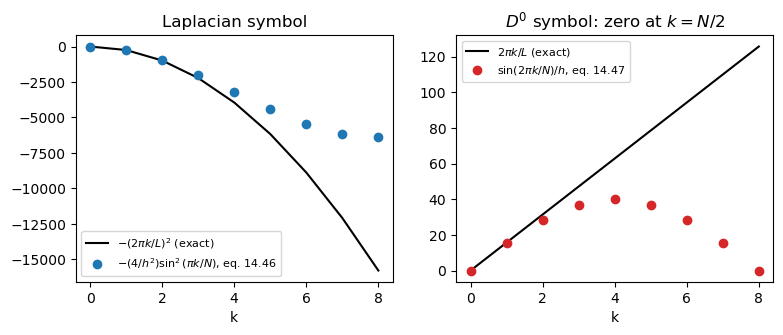

max |D0 . w| before projection 125.11, after 2.7e-14
box mean of u: before -0.024137, after -0.024137 (the k = 0 mode passes through, eq. 14.53)
checkerboard (-1)^i: max |D0_x| = 0.0e+00; change under projection 0.0e+00


In [6]:
from pyibm.fluid.periodic_fft import periodic_symbols

sym = periodic_symbols(g16.Nx, g16.Ny, g16.dx)
print("degenerate modes (k1, k2):", [tuple(int(v) for v in k) for k in np.argwhere(sym.degenerate)])

# A(k) of eq. 14.50 for the 2008 parameters (rho = 2, mu = 3, dt = h^2/nu)
sol16 = PeriodicFFTSolver(g16, rho=2.0, mu=3.0, dt=g16.dx**2 / 1.5)
A = 1.0 / sol16.inv_A_pm1996
print(f"A(k) ranges from {A.min():.4f} at k = 0 to {A.max():.4f} at k = (N/2, N/2); never below 1, so 1/A(k) only damps")

# the 1-D symbols against the continuous ones
N, h, L = g16.Nx, g16.dx, g16.Lx
k = np.arange(N // 2 + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
ax1.plot(k, -(2 * np.pi * k / L) ** 2, "k-", label=r"$-(2\pi k/L)^2$ (exact)")
ax1.plot(k, -(4 / h**2) * np.sin(np.pi * k / N) ** 2, "C0o", label=r"$-(4/h^2)\sin^2(\pi k/N)$, eq. 14.46")
ax1.set_xlabel("k"); ax1.set_title("Laplacian symbol"); ax1.legend(fontsize=8)
ax2.plot(k, 2 * np.pi * k / L, "k-", label=r"$2\pi k/L$ (exact)")
ax2.plot(k, np.sin(2 * np.pi * k / N) / h, "C3o", label=r"$\sin(2\pi k/N)/h$, eq. 14.47")
ax2.set_xlabel("k"); ax2.set_title(r"$D^0$ symbol: zero at $k = N/2$"); ax2.legend(fontsize=8)
plt.show()

# the projection: divergence-free afterwards, box mean untouched, checkerboard untouched
rng = np.random.default_rng(2)
wu, wv = rng.standard_normal(g16.shape_p()), rng.standard_normal(g16.shape_p())
pu_hat, pv_hat = PeriodicFFTSolver.project(np.fft.fft2(wu), np.fft.fft2(wv), sym)
pu, pv = np.real(np.fft.ifft2(pu_hat)), np.real(np.fft.ifft2(pv_hat))
print(f"max |D0 . w| before projection {np.max(np.abs(divergence(wu, wv, h))):.2f}, after {np.max(np.abs(divergence(pu, pv, h))):.1e}")
print(f"box mean of u: before {wu.mean():+.6f}, after {pu.mean():+.6f} (the k = 0 mode passes through, eq. 14.53)")
checker = (-1.0) ** np.arange(N)[:, None] * np.ones(g16.shape_p())      # (-1)^(j1), the example on p. 325
cu_hat, _ = PeriodicFFTSolver.project(np.fft.fft2(checker), np.fft.fft2(0 * checker), sym)
print(f"checkerboard (-1)^i: max |D0_x| = {np.max(np.abs(d0x(checker, h))):.1e}; change under projection {np.max(np.abs(np.real(np.fft.ifft2(cu_hat)) - checker)):.1e}")

## 6. Velocity interpolation and the complete time step (eqs. 14.54-14.61)

Once $u^{n+1}$ is known, the markers move with the fluid at the interpolated velocity (eq. 14.54, repeated as eq. 14.61):

$$X^{n+1}(s) = X^n(s) + \Delta t \sum_x u^{n+1}(x)\, \delta_h\big(x - X^n(s)\big)\, h^3 ,$$

the **new** velocity evaluated at the **old** positions with the same $\delta_h$ weights that spread the force. The summary on pp. 323-324 is the whole step: forces from $X^n$ (eqs. 14.55-14.57), spread (eq. 14.58), solve for $(u^{n+1}, p^{n+1})$ (eqs. 14.59-14.60), interpolate and move (eq. 14.61). Forward Euler for $X$, so the scheme is first order in time.

`DeltaCoupling.interpolate(field, X, layout)` is eq. 14.61 with the $h^2$ weight; `interpolate_vector` does both components. Because spreading and interpolation share the same index and weight tables, they are exactly adjoint with respect to the inner products $\sum_{ij}(\cdot)(\cdot)\,h^2$ on the grid and $\sum_k (\cdot)(\cdot)\, \Delta s_k$ on the markers, which is what makes the power the structure puts in equal the power the fluid takes out (Peskin 2002 section 5, eqs. 5.1-5.2). The time loop itself is `Simulation._step_pm1996` in `pyibm.driver`, in exactly the paper's order; its docstring lists the steps.

In [7]:
import inspect
from pyibm.driver import Simulation

rng = np.random.default_rng(3)
Nm = 40
Xm = rng.uniform(0.0, g16.Lx, (Nm, 2))              # markers anywhere in the box (the stencils wrap)
fm = rng.standard_normal(Nm)
dsm = np.full(Nm, g16.dx / 2)
ug = rng.standard_normal(g16.shape_p())

Fm = dc.spread(fm, Xm, dsm, lay16)                   # eq. 14.58
Um = dc.interpolate(ug, Xm, lay16)                   # eq. 14.61
lhs = np.sum(Fm * ug) * g16.dx * g16.dy              # (spread f, u)_grid
rhs = np.sum(fm * dsm * Um)                          # (f, interp u)_markers
print(f"adjointness: {lhs:.15f} vs {rhs:.15f}, relative difference {abs(lhs - rhs) / abs(lhs):.1e}")
print(f"constants interpolate exactly (eq. 14.66): max error {np.max(np.abs(dc.interpolate(np.full(g16.shape_p(), 3.0), Xm, lay16) - 3.0)):.1e}")

print(inspect.getdoc(Simulation._step_pm1996))

adjointness: -0.027650100639233 vs -0.027650100639233, relative difference 2.5e-16
constants interpolate exactly (eq. 14.66): max error 1.3e-15
Peskin & McQueen 1996 eqs. 14.55-14.61:

1. hooks with t; f at X^n plus lagrangian_force; F = spread(f, X^n);
   F += external_force.
2. solver.step(F): upwind advection, backward Euler, projection; blob: p += p_F.
3. U = interp(u^{n+1}, X^n); X^{n+1} = wrap(X^n + dt U); ghosts by symplectic Euler.

This is the order of the 2008 MATLAB loop (moveplate, target_force, forcespread,
fluid_solve, move_boundary), which is why the regression test reproduces it.


## 7. The smoothed delta function and the 4-point kernel (eqs. 14.62-14.73): `pyibm.kernels`

Section 14.5 builds $\delta_h$ as a product of one-dimensional kernels, $\delta_h(x) = h^{-3}\,\phi(x_1/h)\,\phi(x_2/h)\,\phi(x_3/h)$ (eq. 14.62), and fixes $\phi$ by five postulates:

1. $\phi$ is continuous (no jumps as a marker crosses a cell);
2. $\phi(r) = 0$ for $|r| \ge 2$ (the smallest support compatible with the rest);
3. $\sum_{j\ \mathrm{even}} \phi(r - j) = \sum_{j\ \mathrm{odd}} \phi(r - j) = \tfrac12$ for all $r$ (eq. 14.63);
4. $\sum_j (r - j)\,\phi(r - j) = 0$ for all $r$ (eq. 14.64, the first moment);
5. $\sum_j \phi(r - j)^2 = C$ independent of $r$ (eq. 14.65).

Postulate 3 implies $\sum_j \phi(r - j) = 1$ (eq. 14.66): spreading conserves total force and interpolation reproduces constants. The paper asks for the stronger even/odd form because of the checkerboards of section 5: with eq. 14.63 the spread force has a Fourier transform that vanishes whenever any $k_\alpha = N/2$, so a localised force cannot excite the oscillations that $D^0$ is blind to (p. 325). Postulate 4 with eq. 14.66 gives $\sum_j j\,\phi(r - j) = r$ (eq. 14.68): linear fields are interpolated exactly and each force element applies the right torque. Postulate 5 gives the Schwarz bound $\sum_j \phi(r_1 - j)\phi(r_2 - j) \le C$ (eq. 14.67): a marker's influence on itself is the same wherever it sits relative to the lattice. Writing the postulates out on $r \in [0, 1]$ (eqs. 14.69-14.72) gives $\phi(0) = \tfrac12$, $\phi(\pm1) = \tfrac14$, $C = \tfrac38$, and a quadratic whose continuous root is the closed form (eq. 14.73)

$$\phi(r) = \begin{cases} \big(3 - 2|r| + \sqrt{1 + 4|r| - 4r^2}\big)/8, & |r| \le 1,\\ \big(5 - 2|r| - \sqrt{-7 + 12|r| - 4r^2}\big)/8, & 1 \le |r| \le 2,\\ 0, & |r| \ge 2.\end{cases}$$

pyIBM keeps three kernels behind `get_kernel(name)`:

- `peskin4`: eq. 14.73 (Peskin 2002 eq. 6.27), the default. The radicands are clamped at zero before the square root so round-off at $r = 1, 2$ cannot give NaN.
- `cosine4`: Peskin's 1977 kernel $\phi(r) = \tfrac14(1 + \cos\tfrac{\pi r}{2})$ for $|r| < 2$. This is what my 2008 code used (`forcespread.m`, `move_boundary.m`). Peskin 2002 eq. 6.28 says it satisfies every postulate except the first-moment condition, so it conserves force and has the same $C = 3/8$ but does not interpolate linear fields exactly. It stays in pyIBM for one reason: to reproduce the 2008 results bit for bit (section 10).
- `roma3`: the 3-point kernel of Roma, Peskin & Berger 1999, with $\phi(0) = \tfrac23$ and support $|r| < \tfrac32$. It drops postulate 3 (keeping only the sum, the first moment and a constant $C = \tfrac12$), which Peskin 2002 pp. 26-27 recommends only with a scheme that has no checkerboard null space, that is the staggered MAC grid of notebook 02. pyIBM allows it on the MAC back end only.

`stencil_1d(kernel, X, x0, h, n, periodic)` turns marker coordinates into the (index, weight) tables along one axis, with the distance taken from the unwrapped index and the index wrapped modulo $n$; the coupling of sections 2 and 6 is the tensor product of two of these. We now check the postulates numerically for all three kernels, then show what failing postulate 3 does to the spread force in Fourier space, and what failing postulate 4 does to interpolation.

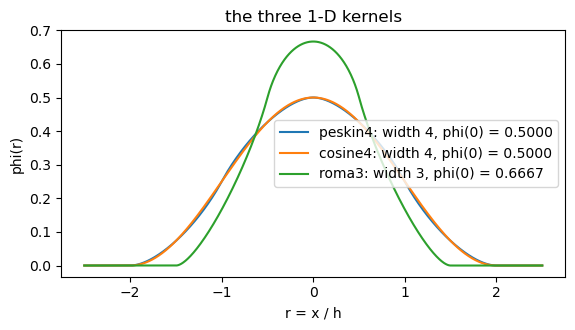

kernel     max|sum phi - 1|  max|even - 1/2|  max|odd - 1/2|  max|1st moment|   sum phi^2 (min, max)
peskin4             3.3e-16          2.2e-16         2.2e-16          4.6e-16      0.3750     0.3750
cosine4             2.2e-16          2.2e-16         2.2e-16          2.1e-02      0.3750     0.3750
roma3               2.2e-16          1.7e-01         1.7e-01          2.1e-16      0.5000     0.5000
eq. 14.66 (sum = 1): all three; eq. 14.63 (even/odd): peskin4 and cosine4 only; eq. 14.64 (first moment): peskin4 and roma3 only;
eq. 14.65 (sum of squares): C = 3/8 for the 4-point kernels, 1/2 for roma3.


In [8]:
from pyibm.kernels import get_kernel

kernels = {name: get_kernel(name) for name in ("peskin4", "cosine4", "roma3")}
r_plot = np.linspace(-2.5, 2.5, 1001)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for name, ker in kernels.items():
    ax.plot(r_plot, ker.phi(r_plot), label=f"{name}: width {ker.width}, phi(0) = {ker.phi(0.0):.4f}")
ax.set_xlabel("r = x / h"); ax.set_ylabel("phi(r)"); ax.legend(); ax.set_title("the three 1-D kernels")
plt.show()

rng = np.random.default_rng(4)
r = rng.uniform(0.0, 1.0, 5000)                 # the shift of a marker relative to the lattice
j = np.arange(-3, 4)                            # enough nodes to cover every support
print(f"{'kernel':8s} {'max|sum phi - 1|':>18s} {'max|even - 1/2|':>16s} {'max|odd - 1/2|':>15s} {'max|1st moment|':>16s} {'sum phi^2 (min, max)':>22s}")
for name, ker in kernels.items():
    vals = ker.phi(r[:, None] - j[None, :])         # phi(r - j), shape (5000, 7)
    total = vals.sum(axis=1)
    even = vals[:, j % 2 == 0].sum(axis=1)
    odd = vals[:, j % 2 == 1].sum(axis=1)
    moment = ((r[:, None] - j[None, :]) * vals).sum(axis=1)
    sq = (vals**2).sum(axis=1)
    print(f"{name:8s} {np.max(np.abs(total - 1)):18.1e} {np.max(np.abs(even - 0.5)):16.1e} {np.max(np.abs(odd - 0.5)):15.1e} "
          f"{np.max(np.abs(moment)):16.1e} {sq.min():11.4f} {sq.max():10.4f}")
print("eq. 14.66 (sum = 1): all three; eq. 14.63 (even/odd): peskin4 and cosine4 only; eq. 14.64 (first moment): peskin4 and roma3 only;")
print("eq. 14.65 (sum of squares): C = 3/8 for the 4-point kernels, 1/2 for roma3.")

In [9]:
# What postulate 3 buys: the spread force of random point forces has no Fourier content at k = N/2
rng = np.random.default_rng(5)
Xk = rng.uniform(0.0, g16.Lx, (40, 2)); fk = rng.standard_normal(40); dsk = np.full(40, g16.dx / 2)
print(f"{'kernel':8s} {'max |F_hat| at k1 = N/2':>24s} {'at k2 = N/2':>14s} {'max |F_hat| overall':>20s}")
for name in kernels:
    F_hat = np.fft.fft2(DeltaCoupling(name).spread(fk, Xk, dsk, lay16))
    print(f"{name:8s} {np.max(np.abs(F_hat[g16.Nx // 2, :])):24.1e} {np.max(np.abs(F_hat[:, g16.Ny // 2])):14.1e} {np.max(np.abs(F_hat)):20.1f}")
print("roma3 puts O(1) force into the checkerboard modes, which the projection of section 5 cannot remove: that is why it is MAC-only.")

# What postulate 4 buys: a linear field is interpolated exactly. The markers stay 2h from the box
# edges because the linear field is not periodic and a wrapped stencil would read the far side.
Xg, Yg = g16.meshgrid("nodes")
linear = 2.0 + 3.0 * Xg - 1.5 * Yg
Xl = rng.uniform(2 * g16.dx, g16.Lx - 2 * g16.dx, (200, 2))
for name in kernels:
    U = DeltaCoupling(name).interpolate(linear, Xl, lay16)
    print(f"{name:8s} max error interpolating 2 + 3x - 1.5y: {np.max(np.abs(U - (2.0 + 3.0 * Xl[:, 0] - 1.5 * Xl[:, 1]))):.1e}")

kernel    max |F_hat| at k1 = N/2    at k2 = N/2  max |F_hat| overall
peskin4                   1.4e-14        8.9e-15                169.1
cosine4                   1.4e-14        7.1e-15                169.1
roma3                     3.5e+01        3.7e+01                169.1
roma3 puts O(1) force into the checkerboard modes, which the projection of section 5 cannot remove: that is why it is MAC-only.
peskin4  max error interpolating 2 + 3x - 1.5y: 1.3e-15
cosine4  max error interpolating 2 + 3x - 1.5y: 2.4e-03
roma3    max error interpolating 2 + 3x - 1.5y: 1.3e-15


## 8. Peskin 2002 section 7: the second-order midpoint scheme

The 1996 scheme is first order in time: upwind advection, forward Euler for $X$ and backward Euler for viscosity are each first order. Peskin (2002, *Acta Numerica*, section 7) replaces it with a Runge-Kutta midpoint rule (eqs. 7.2-7.3: $y^{n+1/2} = y^n + \tfrac{\Delta t}{2} f(y^n)$, then $y^{n+1} = y^n + \Delta t\, f(y^{n+1/2})$), applied to the immersed boundary as follows.

**Preliminary substep.** Move the markers half a step with the current velocity, $X^{n+1/2} = X^n + \tfrac{\Delta t}{2}\sum_x u^n \delta_h(x - X^n) h^3$ (eq. 7.4); evaluate the forces there (eq. 7.5) and spread them with $\delta_h(x - X^{n+1/2})$ (eqs. 7.6-7.7); advance the fluid over $\Delta t/2$, forward Euler in the advection term and backward Euler in everything else (eqs. 7.8-7.9):

$$\rho\left[\frac{u^{n+1/2} - u^n}{\Delta t/2} + S_h(u^n)\,u^n\right] + D^0\tilde p = \mu L_h u^{n+1/2} + f^{n+1/2}, \qquad D^0\cdot u^{n+1/2} = 0 .$$

**Final substep.** Move the markers the full step with the half-step velocity at the half-step positions, $X^{n+1} = X^n + \Delta t \sum_x u^{n+1/2}\delta_h(x - X^{n+1/2}) h^3$ (eq. 7.10); advance the fluid over $\Delta t$ with the advection evaluated at the half step and Crank-Nicolson viscosity, same force (eqs. 7.11-7.12):

$$\rho\left[\frac{u^{n+1} - u^n}{\Delta t} + S_h(u^{n+1/2})\,u^{n+1/2}\right] + D^0 p^{n+1/2} = \mu L_h \frac{u^n + u^{n+1}}{2} + f^{n+1/2}, \qquad D^0\cdot u^{n+1} = 0 .$$

Two ingredients changed besides the time stepping. The advection operator is the skew-symmetric form $S_h(u)\phi = \tfrac12 u\cdot D^0\phi + \tfrac12 D^0\cdot(u\phi)$ (eq. 4.10), which is skew-adjoint for every $u$, divergence-free or not (eq. 4.14), so the semi-discrete scheme conserves energy up to viscous dissipation (eq. 5.15) and momentum (eq. 5.12). And the Laplacian is the tight five-point $L_h$ (eq. 4.8), not $D^0\cdot D^0$, whose stencil is four mesh widths wide and has its own checkerboard null space. Both substeps are again constant-coefficient and periodic, so the FFT machinery of section 5 solves them, with the same symbols and the same four degenerate modes.

In pyIBM: `skew_advection(u, v)` is eq. 4.10; `half_step(Fu, Fv, t)` is eqs. 7.8-7.9 and returns $(u^{n+1/2}, v^{n+1/2})$ without touching the state; `full_step(Fu, Fv, u_h, v_h, t)` is eqs. 7.11-7.12. Both use $A_h(k) = 1 + \tfrac{2\mu\Delta t}{\rho h^2}\sum\sin^2$ (`inv_A_mid`): backward Euler over $\Delta t/2$ and Crank-Nicolson over $\Delta t$ have the same implicit operator. The driver's `_step_midpoint` is eqs. 7.4-7.12 in order and is the default `time_scheme` on both back ends. First the shear wave of section 3 again, now with the midpoint scheme next to the upwind one, then a Taylor-Green vortex to measure the temporal orders.

max v after 32 steps: exact 0.9985, upwind 0.7864, midpoint 0.9950
energy of the ridge: initial 0.05013, upwind 0.03948, midpoint 0.05023
(mu = 0: the skew-symmetric operator conserves the semi-discrete energy; the upwind operator dissipates it;
 the RK2 time step itself changes it only at O(dt^2) per step)


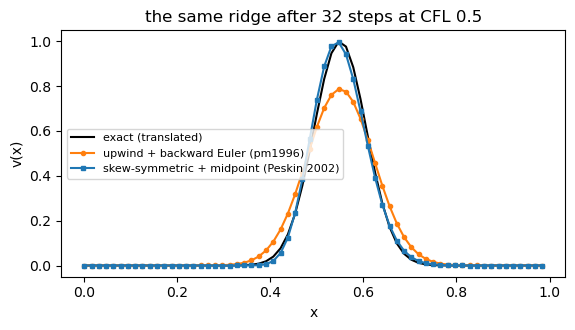

In [10]:
s_mid = advect_ridge("midpoint")
print(f"max v after {n_adv} steps: exact {exact.max():.4f}, upwind {s_up.v.max():.4f}, midpoint {s_mid.v.max():.4f}")
E = lambda s: 0.5 * np.sum(s.v**2) * g_adv.dx**2
print(f"energy of the ridge: initial {0.5 * np.sum(ridge**2) * g_adv.dx**2:.5f}, upwind {E(s_up):.5f}, midpoint {E(s_mid):.5f}")
print("(mu = 0: the skew-symmetric operator conserves the semi-discrete energy; the upwind operator dissipates it;")
print(" the RK2 time step itself changes it only at O(dt^2) per step)")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(g_adv.x, exact[:, 0], "k-", label="exact (translated)")
ax.plot(g_adv.x, s_up.v[:, 0], "C1o-", ms=3, label="upwind + backward Euler (pm1996)")
ax.plot(g_adv.x, s_mid.v[:, 0], "C0s-", ms=3, label="skew-symmetric + midpoint (Peskin 2002)")
ax.set_xlabel("x"); ax.set_ylabel("v(x)"); ax.legend(fontsize=8); ax.set_title("the same ridge after 32 steps at CFL 0.5")
plt.show()

### Taylor-Green decay and the measured temporal orders

The Taylor-Green vortex $u = -U_0\cos 2\pi x \sin 2\pi y\, e^{-8\pi^2\nu t}$, $v = U_0 \sin 2\pi x \cos 2\pi y\, e^{-8\pi^2\nu t}$ is an exact solution of the Navier-Stokes equations on the unit periodic box: the nonlinear term is a pure gradient, so the vortex only decays. On the lattice it is an eigenmode of $L_h$ with eigenvalue $-\lambda_h = -(4/h^2)\cdot 2\sin^2(\pi h)$, and its skew-symmetric advection is a discrete gradient that the projection removes, so the midpoint scheme should decay it at the semi-discrete rate exactly, $O(\Delta t^2)$ aside. The upwind scheme decays it a little faster, because the one-sided differences add numerical viscosity.

We run both schemes with no force on $32^2$ nodes, compare the kinetic-energy decay rate with $2\cdot 8\pi^2\nu$, and measure the temporal order by Richardson extrapolation on three time steps ($\Delta t$, $\Delta t/2$, $\Delta t/4$: the spatial error is identical in all three runs, so the ratio of successive differences isolates the time error). A converged study would use $128^2$ nodes and a longer time; this one is enough to read off slopes 1 and 2.

exact energy decay rate 16 pi^2 nu = 3.1583 1/s; semi-discrete rate 2 lambda_h = 3.1481 1/s (the O(h^2) gap of the five-point Laplacian)
pm1996    measured rate 3.1740 1/s; max |u - exact| at t = 0.5 is 9.16e-05 (U0 = 0.05)
midpoint  measured rate 3.1482 1/s; max |u - exact| at t = 0.5 is 5.75e-05 (U0 = 0.05)
pm1996    |u(dt) - u(dt/2)| = 8.595e-05, |u(dt/2) - u(dt/4)| = 4.357e-05  ->  measured temporal order 0.980
midpoint  |u(dt) - u(dt/2)| = 7.118e-07, |u(dt/2) - u(dt/4)| = 1.779e-07  ->  measured temporal order 2.000


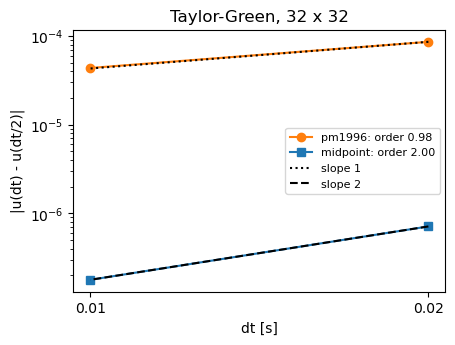

In [11]:
g_tg = Grid.periodic_box(1.0, 1.0, 32, 32)
rho_tg, mu_tg, U0_tg = 1.0, 0.02, 0.05
nu_tg = mu_tg / rho_tg
zero_tg = np.zeros(g_tg.shape_p())


def taylor_green(t):
    X, Y = g_tg.meshgrid("nodes")
    e = np.exp(-8 * np.pi**2 * nu_tg * t)
    return (-U0_tg * np.cos(2 * np.pi * X) * np.sin(2 * np.pi * Y) * e,
            U0_tg * np.sin(2 * np.pi * X) * np.cos(2 * np.pi * Y) * e)


def run_taylor_green(scheme, dt, T):
    s = PeriodicFFTSolver(g_tg, rho_tg, mu_tg, dt)
    s.u, s.v = taylor_green(0.0)
    for _ in range(int(round(T / dt))):
        if scheme == "pm1996":
            s.step(zero_tg, zero_tg, 0.0)
        else:
            u_h, v_h = s.half_step(zero_tg, zero_tg, 0.0)
            s.full_step(zero_tg, zero_tg, u_h, v_h, 0.0)
    return s


# decay rate of the kinetic energy over T = 0.5 at dt = 0.005
T_decay, dt_decay = 0.5, 0.005
u0, v0 = taylor_green(0.0)
E0 = 0.5 * rho_tg * np.sum(u0**2 + v0**2) * g_tg.dx**2
lam_h = nu_tg * (4 / g_tg.dx**2) * 2 * np.sin(np.pi * g_tg.dx) ** 2
print(f"exact energy decay rate 16 pi^2 nu = {16 * np.pi**2 * nu_tg:.4f} 1/s; semi-discrete rate 2 lambda_h = {2 * lam_h:.4f} 1/s (the O(h^2) gap of the five-point Laplacian)")
for scheme in ("pm1996", "midpoint"):
    s = run_taylor_green(scheme, dt_decay, T_decay)
    rate = -np.log(s.kinetic_energy() / E0) / T_decay
    ua, va = taylor_green(T_decay)
    print(f"{scheme:9s} measured rate {rate:.4f} 1/s; max |u - exact| at t = {T_decay} is {np.max(np.abs(s.u - ua)):.2e} (U0 = {U0_tg})")

# temporal order by Richardson extrapolation over T = 0.2
T_ord = 0.2
dts = (0.02, 0.01, 0.005)
orders, diffs = {}, {}
for scheme in ("pm1996", "midpoint"):
    us = [run_taylor_green(scheme, dt, T_ord).u for dt in dts]
    d1 = np.max(np.abs(us[0] - us[1]))
    d2 = np.max(np.abs(us[1] - us[2]))
    orders[scheme] = np.log2(d1 / d2)
    diffs[scheme] = (d1, d2)
    print(f"{scheme:9s} |u(dt) - u(dt/2)| = {d1:.3e}, |u(dt/2) - u(dt/4)| = {d2:.3e}  ->  measured temporal order {orders[scheme]:.3f}")

fig, ax = plt.subplots(figsize=(4.8, 3.4))
for scheme, mk in (("pm1996", "C1o-"), ("midpoint", "C0s-")):
    ax.loglog(dts[:2], diffs[scheme], mk, label=f"{scheme}: order {orders[scheme]:.2f}")
ax.loglog(dts[:2], diffs["pm1996"][0] * (np.array(dts[:2]) / dts[0]), "k:", label="slope 1")
ax.loglog(dts[:2], diffs["midpoint"][0] * (np.array(dts[:2]) / dts[0]) ** 2, "k--", label="slope 2")
ax.set_xticks(dts[:2], [str(d) for d in dts[:2]], minor=False); ax.set_xticks([], minor=True)
ax.set_xlabel("dt [s]"); ax.set_ylabel("|u(dt) - u(dt/2)|"); ax.legend(fontsize=8); ax.set_title("Taylor-Green, 32 x 32")
plt.show()

## 9. Target points as tethers: `pyibm.structures`

Peskin 2002 (p. 33) describes how to put a rigid or prescribed-motion body into the method: tie each marker to a target position with a stiff spring, and move the targets to move the body (Lai & Peskin 2000; Goldstein, Handler & Sirovich 1993). That is exactly how the 2008 code held and moved its plate (`target_force.m`), and it is the `Targets` element of `pyibm.structures`: marker `idx` is tethered to the prescribed position `X` with stiffness `k`, and the force is

$$f_i = k\,(X_T - X_i) = -\frac{\partial}{\partial X_i}\,\frac{k}{2}\,|X_T - X_i|^2 ,$$

with the separation taken as the minimum image. Like every force in pyIBM, $f$ is a force **per unit length** of boundary (N/m), so `k` is a force per unit length per metre of displacement (N/m$^2$); the force a point actually puts on the fluid is $k\,(X_T - X_i)\,\Delta s$, because spreading multiplies by `ds` (section 2). `compute_forces(structure, grid, t, dt)` adds up every element type (springs, damped springs, beams, targets, mass tethers), each as $-\partial E/\partial X$ of its energy, and the energy functions (`target_energy` and friends) exist so that tests can check every force against a finite difference of the energy. Prescribed motion goes through a hook: the driver calls `update_targets(t, dt, s)` from the case's `hooks.py` with the time at which the forces are evaluated, and the hook sets `s.targets.X` as a function of absolute time.

Explicit tethers limit the time step. Stockie & Wetton (1999, J. Comput. Phys. 154, 41-64) analyse why: with explicit fibre forces the largest stable time step falls as the stiffness grows, and they work out the limit for a stretched elastic fibre. How stiff a tether may be at a given $\Delta t$ depends on the set-up, so pyIBM does not enforce a limit. It measures the stiffness with the tether number $k\,\Delta t^2/(\rho\,\Delta x)$ and warns once when the stiffest target point or mass tether is above the largest value at which our own test runs stayed stable (`pyibm.driver.TETHER_STABLE`, printed below; the `pyibm.driver` module docstring describes the test). That warning is a rule of thumb, a reason to check $\Delta t$ or $k$, not a stability limit. The driver also reports the largest distance between a marker and its target in cells as `max_target_error_over_dx` in the history. We build the 2008 plate by hand here (16 points on a vertical line, $\Delta s = \Delta x/2$), nudge the targets by one millimetre, and look at the numbers.

force density on the first point: [10.  0.] N/m  (k * 1e-3 = 10.0 N/m)
total force on the fluid sum f ds: [2. 0.] N
-dE/dX by finite difference 10.000000000 vs target_forces 10.000000000
sum Fx h^2 = 2.000000 N, sum Fy h^2 = 0.0e+00 N
tether number k dt^2/(rho dx) for the 2008 dt = 4.167e-04 s, rho = 2: 0.035; the driver's rule of thumb warns above 10 for target points and 7 for mass tethers


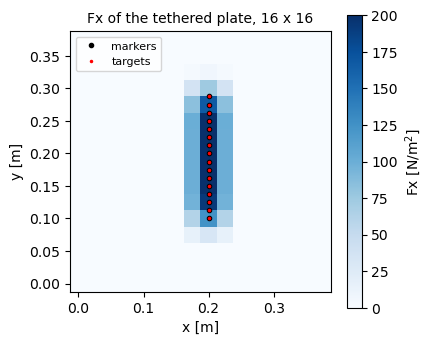

In [12]:
from pyibm.structures import Structure, Targets, target_forces, target_energy, compute_forces

ds_plate = g16.dx / 2
X_plate = np.column_stack([np.full(16, 0.2), 0.1 + ds_plate * np.arange(16)])
k_target = 1e4                                     # N/m per m of displacement
plate = Structure("plate", X_plate, ds=np.full(16, ds_plate),
                  targets=Targets(idx=np.arange(16), k=np.full(16, k_target), X=X_plate.copy()))
plate.targets.X[:, 0] += 1e-3                      # targets one millimetre to the right of the markers

f = compute_forces(plate, g16, t=0.0, dt=1.0)      # here only the targets contribute
print(f"force density on the first point: {f[0]} N/m  (k * 1e-3 = {k_target * 1e-3} N/m)")
print(f"total force on the fluid sum f ds: {(f * plate.ds[:, None]).sum(axis=0)} N")

# the force is -dE/dX: central finite difference of the target energy on one coordinate
i, eps = 5, 1e-6
Xp, Xm = plate.X.copy(), plate.X.copy()
Xp[i, 0] += eps; Xm[i, 0] -= eps
fd = -(target_energy(Xp, plate.targets, g16) - target_energy(Xm, plate.targets, g16)) / (2 * eps)
print(f"-dE/dX by finite difference {fd:.9f} vs target_forces {target_forces(plate.X, plate.targets, g16)[i, 0]:.9f}")

# spread to the lattice: the plate becomes a band four cells wide; the total force survives
Fx, Fy = dc.spread_vector(f, plate.X, plate.ds, lay16, lay16)
print(f"sum Fx h^2 = {Fx.sum() * g16.dx**2:.6f} N, sum Fy h^2 = {Fy.sum() * g16.dx**2:.1e} N")
dt_2008 = g16.dx**2 / 1.5
from pyibm.driver import TETHER_STABLE
print(f"tether number k dt^2/(rho dx) for the 2008 dt = {dt_2008:.3e} s, rho = 2: {k_target * dt_2008**2 / (2.0 * g16.dx):.3f}; "
      f"the driver's rule of thumb warns above {TETHER_STABLE[('target', 'pm1996')]:g} for target points "
      f"and {TETHER_STABLE[('mass tether', 'pm1996')]:g} for mass tethers")

fig, ax = plt.subplots(figsize=(4.2, 3.8))
m = ax.pcolormesh(g16.x, g16.y, Fx.T, shading="nearest", cmap="Blues")
ax.plot(plate.X[:, 0], plate.X[:, 1], "k.", label="markers"); ax.plot(plate.targets.X[:, 0], plate.targets.X[:, 1], "r.", ms=3, label="targets")
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Fx of the tethered plate, 16 x 16", fontsize=10); fig.colorbar(m, ax=ax, label="Fx [N/m$^2$]")
plt.show()

In a case directory the same structure is two text files, `<name>.vertex` (count, then `x y` per point) and `<name>.target` (count, then `index stiffness` per row, with an optional third column for a damping coefficient), read by `read_structure(case_dir, name, ds=...)`; the motion is `hooks.py`. The 2008 case ships both, so we look at them rather than retype them.

In [13]:
from pyibm.structures import read_structure, load_hooks

CASE = os.path.join(root, "examples", "heaving_plate_2008")
for fname in ("plate_stiff1e4.vertex", "plate_stiff1e4.target"):
    with open(os.path.join(CASE, fname)) as fh:
        lines = fh.read().splitlines()
    print(f"{fname}: {lines[0]} rows; first rows: {lines[1:3]}")
s_file = read_structure(CASE, "plate_stiff1e4", ds=0.0125)
print(f"read_structure: {s_file.n} points, ds = {s_file.ds[0]}, target stiffness {s_file.targets.k[0]:.0f}, same points as above: {np.array_equal(s_file.X, X_plate)}")

hooks = load_hooks(CASE)
print("hooks defined:", hooks.defined())
print(f"X0 = {hooks.module.X0} m, AMPLITUDE = {hooks.module.AMPLITUDE} m, PERIOD = {hooks.module.PERIOD} s")
print(inspect.getsource(hooks.update_targets))

plate_stiff1e4.vertex: 16 rows; first rows: ['0.20000000000000001 0.10000000000000001', '0.20000000000000001 0.1125']
plate_stiff1e4.target: 16 rows; first rows: ['0 10000', '1 10000']
read_structure: 16 points, ds = 0.0125, target stiffness 10000, same points as above: True
hooks defined: ['update_targets']
X0 = 0.2 m, AMPLITUDE = 0.05 m, PERIOD = 10.0 s
def update_targets(t, dt, s):
    phase = 2.0 * np.pi * t / PERIOD
    s.targets.X[:, 0] = X0 + AMPLITUDE * np.sin(phase)
    s.targets.V[:, 0] = AMPLITUDE * (2.0 * np.pi / PERIOD) * np.cos(phase)
    s.targets.V[:, 1] = 0.0



## 10. The 2008 heaving plate against the MATLAB reference

`examples/heaving_plate_2008` is the case my MATLAB code ran: the 16-point plate of section 9, half the box tall, in the $0.4\,\mathrm{m}$ doubly periodic box with $\rho = 2$, $\mu = 3$ (so $\nu = 1.5$, a very viscous fluid; the Reynolds number is printed below), pushed sideways by moving every target as $x_T(t) = 0.2 + 0.05\sin(2\pi t/10)$. The time step is $\Delta t = \Delta x^2/\nu$, written in the input file with the exact floating-point value MATLAB computed, and we run 100 steps. The reference `tests/data/heaving_plate_2008_stiff1e4.mat` holds the state the unmodified 2008 functions saved after steps 1, 2, 3, 5, 10, 25, 50 and 100 (see `tests/data/README.md`): velocity, pressure, spread force, plate positions.

Three input files share the case (`generate.py` writes them): `input2d` has the 2008 settings, with target stiffness $k = 1$; `input2d_stiff1e4` is the same scheme (`pm1996`) and kernel (`cosine4`) with $k = 10^4$, the regression reference; `input2d_midpoint` is $k = 10^4$ with the midpoint scheme and the `peskin4` kernel, the setup we recommend in pyIBM. We first step the reference input through `Simulation` and compare `u`, `v`, `X` and `p` with the MATLAB checkpoints as they go by. Output goes to a temporary directory; a normal run writes to `viz/<variant>` inside the case directory and is started with `python -m pyibm run examples/heaving_plate_2008 --input input2d_stiff1e4`.

In [14]:
import shutil
import scipy.io as sio
from pyibm.inputfile import read_input_file
from pyibm.driver import run

OUT = tempfile.mkdtemp(prefix="pyibm_tutorial01_")
print("output files of this section go to a temporary directory, removed at the end of section 10")
params = read_input_file(os.path.join(CASE, "input2d_stiff1e4"))
print(params.grid, params.fluid, params.time, sep="\n")
print(f"scheme {params.solver.time_scheme}, kernel {params.solver.kernel}, structure {params.structure.name}, steps {params.time.n_steps}")
U_T = hooks.module.AMPLITUDE * 2 * np.pi / hooks.module.PERIOD          # peak target speed [m/s]
L_plate = s_file.n * s_file.ds[0]                                        # 16 points, ds apart [m]
print(f"peak target speed {U_T:.4f} m/s, plate length {L_plate:.3f} m, Re = rho U L / mu = {params.fluid.rho * U_T * L_plate / params.fluid.mu:.4f}")
params.output.save_vtk = False                     # no VTK files from the step loop

ref = sio.loadmat(os.path.join(root, "tests", "data", "heaving_plate_2008_stiff1e4.mat"), simplify_cells=True)
checkpoints = [int(n) for n in np.atleast_1d(ref["params"]["save_steps"])]
print("MATLAB parameters:", {k: ref["params"][k] for k in ("M", "N", "dx", "ds", "dt", "nu", "rho", "stiff")})


def rel_diff(ours, theirs):
    scale = np.max(np.abs(theirs))
    return np.max(np.abs(ours - theirs)) / scale if scale > 0 else np.max(np.abs(ours))


sim = Simulation(params, CASE, output_dir=OUT, quiet=True)
print(f"dt identical bit for bit: {sim.dt == float(ref['params']['dt'])}; initial plate identical: {np.array_equal(sim.structure.X, ref['X0'])}")
snapshots = {}
print(f"\n{'step':>4s} {'t [s]':>10s} {'rel diff u':>11s} {'rel diff v':>11s} {'rel diff X':>11s} {'rel diff p':>11s}")
t0 = time.perf_counter()
for n in range(1, params.time.n_steps + 1):
    sim.step()
    if n in checkpoints:
        s = ref[f"step_{n:04d}"]
        print(f"{n:4d} {sim.t:10.6f} {rel_diff(sim.solver.u, s['u']):11.1e} {rel_diff(sim.solver.v, s['v']):11.1e} "
              f"{rel_diff(sim.structure.X, s['X']):11.1e} {rel_diff(sim.solver.p, s['press']):11.1e}")
    if n in (10, 50, 100):
        snapshots[n] = (sim.solver.vorticity().copy(), sim.structure.X.copy(), sim.structure.targets.X.copy(), sim.t)
print(f"\n100 steps in {time.perf_counter() - t0:.2f} s; the regression test (tests/test_matlab_regression.py) demands 1e-10")

output files of this section go to a temporary directory, removed at the end of section 10
GridParams(Nx=16, Ny=16, Lx=0.4, Ly=0.4)
FluidParams(rho=2.0, mu=3.0)
TimeParams(Tfinal=0.04166666666666667, dt=0.00041666666666666675)
scheme pm1996, kernel cosine4, structure plate_stiff1e4, steps 100
peak target speed 0.0314 m/s, plate length 0.200 m, Re = rho U L / mu = 0.0042
MATLAB parameters: {'M': 16, 'N': 16, 'dx': 0.025, 'ds': 0.0125, 'dt': 0.00041666666666666675, 'nu': 1.5, 'rho': 2, 'stiff': 10000}
dt identical bit for bit: True; initial plate identical: True

step      t [s]  rel diff u  rel diff v  rel diff X  rel diff p
   1   0.000417     0.0e+00     0.0e+00     0.0e+00     0.0e+00
   2   0.000833     7.8e-16     7.0e-16     0.0e+00     5.4e-16
   3   0.001250     7.4e-16     8.5e-16     0.0e+00     6.7e-16
   5   0.002083     6.0e-16     5.6e-16     0.0e+00     5.4e-16
  10   0.004167     6.3e-16     6.6e-16     0.0e+00     5.9e-16
  25   0.010417     6.6e-16     7.9e-16     0.0e

The differences are round-off: NumPy's pocketfft and MATLAB's FFTW round the same arithmetic differently. The scheme is the same operation for operation. The vorticity $\omega = D^0_x v - D^0_y u$ on the nodes (`solver.vorticity()`) shows what the flow looks like: a plate dragged broadside through syrup, with the whole periodic box starting to move along (the mean flow of eq. 14.53, which we come back to below). The built-in `pyibm.io.plot.snapshot` draws the same picture, and `plot = 1` in the input file saves one at every output.

largest |vorticity| in the three frames: 0.3203 1/s


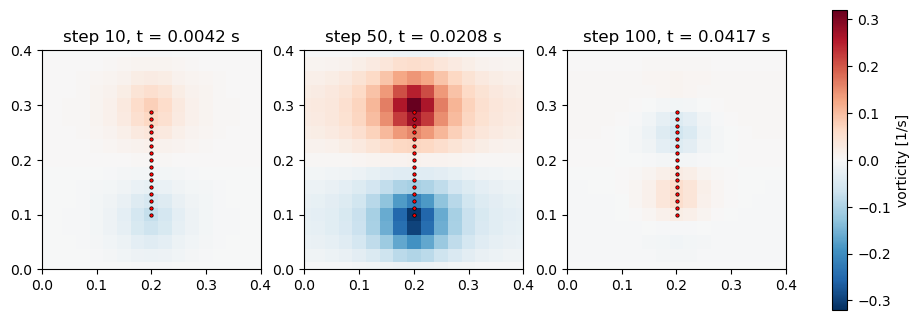

In [15]:
vmax = max(np.max(np.abs(w)) for w, *_ in snapshots.values())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, (n, (omega, Xs, XT, t)) in zip(axes, snapshots.items()):
    x_ext = np.append(g16.x, g16.Lx); y_ext = np.append(g16.y, g16.Ly)         # draw the periodic box fully
    w_ext = np.concatenate([omega, omega[:1]], axis=0); w_ext = np.concatenate([w_ext, w_ext[:, :1]], axis=1)
    m = ax.pcolormesh(x_ext, y_ext, w_ext.T, shading="nearest", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.plot(Xs[:, 0], Xs[:, 1], "k.", ms=4); ax.plot(XT[:, 0], XT[:, 1], "r.", ms=2)
    ax.set_aspect("equal"); ax.set_xlim(0, g16.Lx); ax.set_ylim(0, g16.Ly); ax.set_title(f"step {n}, t = {t:.4f} s")
fig.colorbar(m, ax=axes, label="vorticity [1/s]")
print(f"largest |vorticity| in the three frames: {vmax:.4f} 1/s")
plt.show()

### The 2008 settings, the stiff run, and the second-order run

Now the three inputs through `pyibm.run`, which is what the command line does: it returns a `RunResult` with the history (`step, t, t_force, fx_body, fy_body, max_target_error_over_dx, cfl, mean_u, mean_v, kinetic_energy, max_speed` at step 0, every `print_dump = 5` steps and at the end), the final solver and structure. The force columns hold the force the fluid received during the last step, which the scheme evaluates before the row's `t`: at `t_force` $= t - \Delta t$ for pm1996 and $t - \Delta t/2$ for the midpoint scheme. We plot the forces against `t_force`. We compare the target lag in cells, the largest fluid speed, the $x$ force the fluid puts on the plate, and the wall time.

input                   k    scheme   kernel  max lag [cells]  max speed [m/s]  fx at end [N]  wall [s]


input2d                 1    pm1996  cosine4           0.0523         2.07e-05        -0.0003      0.11


input2d_stiff1e4    10000    pm1996  cosine4           0.0158         5.46e-02        +0.0792      0.11


input2d_midpoint    10000  midpoint  peskin4           0.0158         5.45e-02        +0.0846      0.14

k = 1: the plate hardly moves (max speed above) and its 'lag' is just the distance the targets travelled: 1.31 mm after 0.0417 s
k = 1e4: the two stiff runs lag by 0.0158 and 0.0158 cells: the lag is set by the stiffness, not by the scheme
the force rows of the two stiff runs differ by at most 1.9 % of the peak force, but a row holds the force at t_force = t - dt (pm1996) or t - dt/2 (midpoint)


at the same time level (a row every step, the midpoint force interpolated to the pm1996 t_force) they differ by at most 0.5 %: the first-order against second-order time error at this dt
CFL numbers stay tiny: max 9.1e-04


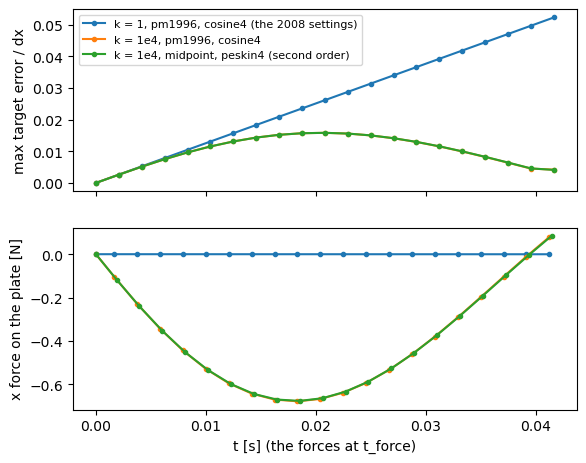

In [16]:
variants = [("input2d", "k = 1, pm1996, cosine4 (the 2008 settings)"),
            ("input2d_stiff1e4", "k = 1e4, pm1996, cosine4"),
            ("input2d_midpoint", "k = 1e4, midpoint, peskin4 (second order)")]
results = {}
print(f"{'input':18s} {'k':>6s} {'scheme':>9s} {'kernel':>8s} {'max lag [cells]':>16s} {'max speed [m/s]':>16s} {'fx at end [N]':>14s} {'wall [s]':>9s}")
for name, label in variants:
    res = run(CASE, input_file=name, quiet=True, output_dir=os.path.join(OUT, name))
    results[name] = res
    hist = res.history
    print(f"{name:18s} {res.structure.targets.k.max():6.0f} {res.parameters.solver.time_scheme:>9s} {res.parameters.solver.kernel:>8s} "
          f"{hist.max_target_error_over_dx.max():16.4f} {hist.max_speed.max():16.2e} {hist.fx_body[-1]:+14.4f} {res.wall_time:9.2f}")

h_soft, h_stiff, h_mid = (results[n].history for n, _ in variants)
print(f"\nk = 1: the plate hardly moves (max speed above) and its 'lag' is just the distance the targets travelled: "
      f"{h_soft.max_target_error_over_dx[-1] * g16.dx * 1e3:.2f} mm after {h_soft.t[-1]:.4f} s")
print(f"k = 1e4: the two stiff runs lag by {h_stiff.max_target_error_over_dx.max():.4f} and {h_mid.max_target_error_over_dx.max():.4f} cells: the lag is set by the stiffness, not by the scheme")
peak = np.max(np.abs(h_stiff.fx_body))
print(f"the force rows of the two stiff runs differ by at most {100 * np.max(np.abs(h_stiff.fx_body - h_mid.fx_body)) / peak:.1f} % of the peak force, "
      f"but a row holds the force at t_force = t - dt (pm1996) or t - dt/2 (midpoint)")
every_step = {}
for name in ("input2d_stiff1e4", "input2d_midpoint"):
    p = read_input_file(os.path.join(CASE, name))
    p.output.print_dump, p.output.save_vtk = 1, False          # a history row every step
    every_step[name] = Simulation(p, CASE, output_dir=os.path.join(OUT, name + "_every_step"), quiet=True).run().history
fa, fb = every_step["input2d_stiff1e4"], every_step["input2d_midpoint"]
same_level = np.max(np.abs(fa.fx_body[1:] - np.interp(fa.t_force[1:], fb.t_force, fb.fx_body))) / peak
print(f"at the same time level (a row every step, the midpoint force interpolated to the pm1996 t_force) they differ by at most "
      f"{100 * same_level:.1f} %: the first-order against second-order time error at this dt")
print(f"CFL numbers stay tiny: max {max(h.cfl.max() for h in (h_soft, h_stiff, h_mid)):.1e}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 5.2), sharex=True)
for (name, label), hist in zip(variants, (h_soft, h_stiff, h_mid)):
    ax1.plot(hist.t, hist.max_target_error_over_dx, "o-", ms=3, label=label)
    ax2.plot(hist.t_force, hist.fx_body, "o-", ms=3, label=label)
ax1.set_ylabel("max target error / dx"); ax1.legend(fontsize=8)
ax2.set_ylabel("x force on the plate [N]"); ax2.set_xlabel("t [s] (the forces at t_force)")
plt.show()

The $x$ force is the fluid's reaction to the impulsive start: it grows while the plate gets up to speed and then relaxes, because nothing anchors the fluid in a periodic box. The target tether is the only force in the system, its box integral is not zero, and the $k = 0$ mode is not projected (eq. 14.53), so the whole box picks up momentum; by the end of the run the box-mean velocity is comparable to the target speed (here it even exceeds it, see the printed numbers), so much of what looks like plate motion is the fluid sloshing along. `remove_mean_force = 1` in the `Solver` block holds the box-mean velocity fixed, in both schemes: every solve sets the $k = 0$ Fourier coefficient of $w$ to that of $u^n$, which removes the box mean of the whole increment of $u$ (force, advection and viscous term). We rerun the second-order input with that switch to show the difference. With the box held still the plate has to push the fluid past it instead of carrying it along, so the drag is several times larger and the tether stretches further: both the force history and the lag change, and the printed lag is the one to quote for a plate of this stiffness in a fluid this viscous.

second-order run at t = 0.0417 s: box-mean u = 0.0525 m/s, target speed = 0.0314 m/s
with remove_mean_force: box-mean u = -4.1e-20 m/s, max lag 0.0486 cells, fx at end -1.8405 N


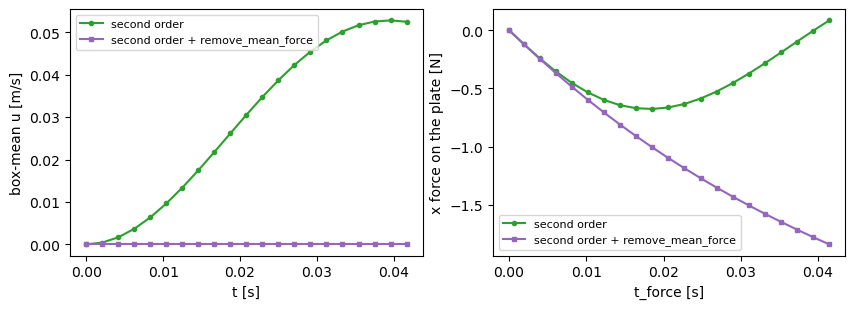

notebook computations so far: 2.0 s


In [17]:
s_end = results["input2d_midpoint"].structure
hooks.update_targets(results["input2d_midpoint"].t, params.time.dt, s_end)   # the target velocity at the final time
print(f"second-order run at t = {h_mid.t[-1]:.4f} s: box-mean u = {h_mid.mean_u[-1]:.4f} m/s, target speed = {s_end.targets.V[0, 0]:.4f} m/s")

params_rm = read_input_file(os.path.join(CASE, "input2d_midpoint"))
params_rm.solver.remove_mean_force = True
params_rm.output.save_vtk = False
res_rm = Simulation(params_rm, CASE, output_dir=os.path.join(OUT, "midpoint_remove_mean"), quiet=True).run()
h_rm = res_rm.history
print(f"with remove_mean_force: box-mean u = {h_rm.mean_u[-1]:.1e} m/s, max lag {h_rm.max_target_error_over_dx.max():.4f} cells, fx at end {h_rm.fx_body[-1]:+.4f} N")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
ax1.plot(h_mid.t, h_mid.mean_u, "C2o-", ms=3, label="second order"); ax1.plot(h_rm.t, h_rm.mean_u, "C4s-", ms=3, label="second order + remove_mean_force")
ax1.set_xlabel("t [s]"); ax1.set_ylabel("box-mean u [m/s]"); ax1.legend(fontsize=8)
ax2.plot(h_mid.t_force, h_mid.fx_body, "C2o-", ms=3, label="second order"); ax2.plot(h_rm.t_force, h_rm.fx_body, "C4s-", ms=3, label="second order + remove_mean_force")
ax2.set_xlabel("t_force [s]"); ax2.set_ylabel("x force on the plate [N]"); ax2.legend(fontsize=8)
plt.show()
shutil.rmtree(OUT, ignore_errors=True)                          # the temporary output of section 10
print(f"notebook computations so far: {time.perf_counter() - t_notebook_start:.1f} s")

## 11. What pyIBM changes from the 2008 code

Before the port we went through the 2008 MATLAB code line by line against the paper, and ran several of the original functions alongside the new ones (`examples/heaving_plate_2008/README.md` summarises what matters for the plate run). The scheme carries over unchanged: upwind switch, Fourier symbols, projection, the four degenerate modes, stencil factors and loop order all follow eqs. 14.34-14.61, which is why section 10 reproduces the saved state to round-off. What pyIBM changes is around the scheme:

- *Vorticity.* `solver.vorticity()` takes periodic differences at every node, edges and corners included, so a plotted frame has no zero border. This is plotting only; nothing feeds back into the run.
- *The periodic wrap.* pyIBM wraps positions with `np.mod` and indexes the stencils with `idx % n`, so the wrap handles every position: a body may leave the box through any face and by any distance. The 2008 wrap covered a marker leaving through the right or top face by less than one period.
- *The time step.* The 2008 inputs set $\Delta t = \Delta x^2/\nu$. With the viscosity implicit, the constraints that bind are the CFL condition of eq. 14.38 and the stiffness of the explicit tethers, so pyIBM writes the CFL number to the history, warns once if it goes above 1, and applies the tether rule of thumb of section 9.
- *The tether.* With $k = 1$ the plate hardly moves (the table in section 10). pyIBM adds the inputs with $k = 10^4$, a stiffer tether, so the plate follows its path.
- *The kernel.* The 2008 code used Peskin's 1977 cosine kernel. pyIBM keeps it for the regression run and uses eq. 14.73 by default, which also satisfies the first-moment postulate of eq. 14.64 (section 7 measures both).
- *Code structure.* pyIBM reads the parameters once, keeps the state in objects instead of globals, defines the box size in one place, makes $\Delta s$ a property of each boundary point, builds the stencil tables in one function (`stencil_1d`, section 7), and takes the pressure from the Fourier solve itself (eq. 14.52).

Three things to keep in mind about the 2008 case itself: the scheme is first order everywhere (section 8 gives the second-order one), the mean flow drifts in a periodic box (`remove_mean_force` above), and the parameters give the small Reynolds number printed in section 10, a plate in syrup rather than a flapping plate (`examples/flapping_plate_re64` is the case for that).

## References

- C. S. Peskin and D. M. McQueen, Fluid dynamics of the heart and its valves, chapter 14 of H. G. Othmer, F. R. Adler, M. A. Lewis and J. C. Dallon (eds.), *Case Studies in Mathematical Modeling: Ecology, Physiology, and Cell Biology* (Prentice Hall, 1996), pp. 313-342.
- C. S. Peskin, The immersed boundary method, *Acta Numerica* 11 (2002) 479-517.
- C. S. Peskin, Numerical analysis of blood flow in the heart, *J. Comput. Phys.* 25 (1977) 220-252.
- A. M. Roma, C. S. Peskin and M. J. Berger, An adaptive version of the immersed boundary method, *J. Comput. Phys.* 153 (1999) 509-534.
- M.-C. Lai and C. S. Peskin, An immersed boundary method with formal second-order accuracy and reduced numerical viscosity, *J. Comput. Phys.* 160 (2000) 705-719.
- D. Goldstein, R. Handler and L. Sirovich, Modeling a no-slip flow boundary with an external force field, *J. Comput. Phys.* 105 (1993) 354-366.
- J. M. Stockie and B. R. Wetton, Analysis of stiffness in the immersed boundary method and implications for time-stepping schemes, *J. Comput. Phys.* 154 (1999) 41-64.